# 02 — Explore the data

We compare the 800 signals from notebook 01: 400 confirmed planets and 400 false positives.

A **signal** is something Kepler spotted that might be a planet: a star dimming again and again at regular times. Each line in our data file is one signal.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("../data/kepler_selected.csv")

RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

FEATURES = ["koi_period", "koi_depth", "koi_duration"]
UNITS = {"koi_period": "days", "koi_depth": "ppm", "koi_duration": "hours"}

# The same two colours in every chart: blue = planet, orange = false positive.
# This pair was checked to stay easy to tell apart for colour-blind readers.
CLASS_ORDER = ["CONFIRMED", "FALSE POSITIVE"]
PALETTE = {"CONFIRMED": "#2a78d6", "FALSE POSITIVE": "#eb6834"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"grid.color": "#e6e5e1", "axes.edgecolor": "#c3c2b7", "figure.dpi": 110})

print(df.shape)
df["koi_disposition"].value_counts()

(800, 9)


koi_disposition
CONFIRMED         400
FALSE POSITIVE    400
Name: count, dtype: int64

## 1. Summary statistics

**How to read it:**
- **mean** = average; **50%** = median, the typical middle value.
- **std**, **min** and **max** show how spread out the values are.
- Compare medians, not means. A few huge values can drag the mean way up.

In [2]:
summary = df.groupby("koi_disposition")[FEATURES + ["koi_srad", "koi_prad"]].describe()

# One small table per measurement, so it's easier to read
for col in FEATURES + ["koi_srad", "koi_prad"]:
    print(f"\n=== {col} ===")
    display(summary[col].round(2))


=== koi_period ===


,count,mean,std,min,25%,50%,75%,max
koi_disposition,,,,,,,,
CONFIRMED,400.0,27.30,56.34,0.66,5.25,11.08,25.96,704.96
FALSE POSITIVE,400.0,65.68,134.30,0.29,1.26,4.15,29.97,559.28



=== koi_depth ===


,count,mean,std,min,25%,50%,75%,max
koi_disposition,,,,,,,,
CONFIRMED,400.0,973.44,1853.19,30.7,219.90,468.00,894.58,16536.0
FALSE POSITIVE,400.0,45441.20,108697.83,7.7,143.33,539.85,22567.75,841900.0



=== koi_duration ===


,count,mean,std,min,25%,50%,75%,max
koi_disposition,,,,,,,,
CONFIRMED,400.0,4.21,2.91,0.76,2.39,3.43,5.05,24.71
FALSE POSITIVE,400.0,6.15,6.56,0.19,2.50,4.03,6.88,56.84



=== koi_srad ===


,count,mean,std,min,25%,50%,75%,max
koi_disposition,,,,,,,,
CONFIRMED,400.0,1.05,0.56,0.19,0.80,0.95,1.17,7.66
FALSE POSITIVE,400.0,1.70,2.93,0.35,0.85,1.01,1.50,35.70



=== koi_prad ===


,count,mean,std,min,25%,50%,75%,max
koi_disposition,,,,,,,,
CONFIRMED,400.0,2.79,3.05,0.50,1.57,2.16,2.89,43.17
FALSE POSITIVE,400.0,40.02,116.73,0.47,1.47,5.80,40.35,1183.06


### What the table shows

- Typical planet: period about 11 days, planet size about 2 Earths.
- Typical false positive: period about 4 days, "planet" size about 6 Earths.
- False positives are far more spread out. They're a mix of things: star pairs, glitches and noise.
- `koi_prad` is calculated from depth, so it mostly repeats the depth information.

**In short:** planets look alike, while false positives are all over the place.

## 2. Do we need a log scale?

- A log axis goes up by ×10 steps (1, 10, 100…) instead of equal steps.
- It stops a few huge values from squashing everything else into one bar.
- Rule: use it when the largest value is over 100 times the smallest.

In [3]:
spread = pd.DataFrame({
    "min": df[FEATURES].min(),
    "max": df[FEATURES].max(),
})
spread["max / min"] = (spread["max"] / spread["min"]).round(0)
spread["use log scale?"] = spread["max / min"] > 100
spread

,min,max,max / min,use log scale?
koi_period,0.29363,704.962626,2401.0,True
koi_depth,7.70000,841900.000000,109338.0,True
koi_duration,0.18660,56.840000,305.0,True


## 3. Histograms: planets vs false positives

**How to read a histogram:**
- Left to right is the value. Bar height is how many signals have that value.
- Blue = planets, orange = false positives. Both groups have 400 signals, so heights compare directly.
- Look for where each colour peaks and where only one colour shows up.

In [4]:
def plot_hist(col, log):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.histplot(
        data=df, x=col, hue="koi_disposition", hue_order=CLASS_ORDER, palette=PALETTE,
        bins=40, log_scale=bool(log), element="step", fill=True, alpha=0.25, linewidth=2,
        common_bins=True, ax=ax,
    )
    scale = " (log scale)" if log else ""
    ax.set_title(f"{col}: planets vs false positives", loc="left", fontsize=13)
    ax.set_xlabel(f"{col} [{UNITS[col]}]{scale}")
    ax.set_ylabel("number of signals")
    ax.get_legend().set_title(None)
    sns.despine(ax=ax)
    fig.tight_layout()
    path = RESULTS / f"hist_{col}.png"
    fig.savefig(path, dpi=150)
    print("saved", path)
    plt.show()

### Orbital period (days between dips)

saved ../results/hist_koi_period.png


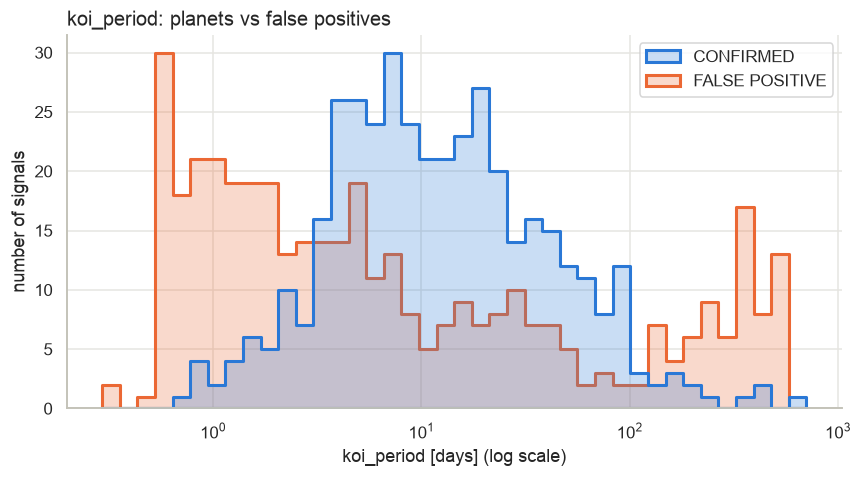

In [5]:
plot_hist("koi_period", log=spread.loc["koi_period", "use log scale?"])

### What this chart shows

- Most planets have periods between about 3 and 100 days.
- Almost half of false positives (44%) have periods under 3 days. These are mostly pairs of stars, which orbit each other very fast.
- There's a second orange bump at very long periods. Long orbits give too few dips to confirm, and some are glitches from Kepler's own trip around the Sun.

**In short:** very short or very long periods suggest a false positive. The middle can't tell you much.

### Transit depth (how much the star dims)

saved ../results/hist_koi_depth.png


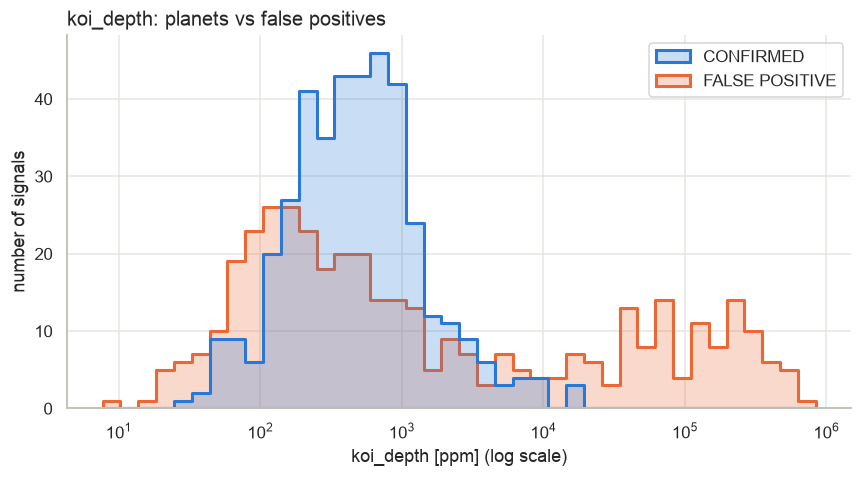

In [6]:
plot_hist("koi_depth", log=spread.loc["koi_depth", "use log scale?"])

### What this chart shows

- Planets almost all make small dips.
- 26% of false positives are deeper than 20,000 ppm (2%), and no planet is.
- Why: even Jupiter covers only about 1% of a Sun-like star. A deeper dip needs another star in front.
- In the middle range, the two groups overlap a lot.

**In short:** very deep dips are always false positives. Otherwise depth alone isn't enough.

### Transit duration (how long each dip lasts)

saved ../results/hist_koi_duration.png


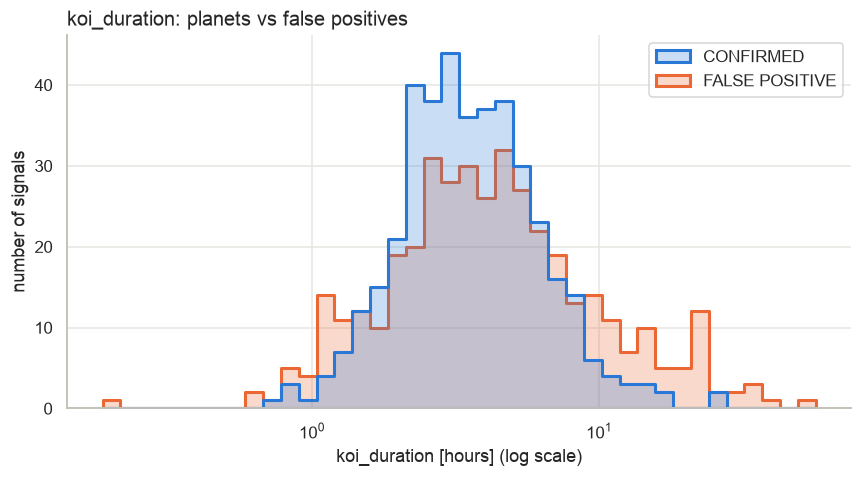

In [7]:
plot_hist("koi_duration", log=spread.loc["koi_duration", "use log scale?"])

### What this chart shows

- Both groups peak at the same place: dips of about 2–6 hours.
- Long dips (over 10 hours) are mostly false positives: 15% of them against 4% of planets.
- Why: a dip lasts longer when the star is huge or the object crossing it is a whole star.

**In short:** duration is the weakest clue on its own. Only very long dips stand out.

## 4. Scatter plot: depth vs duration

**How to read a scatter plot:**
- Each dot is one signal: left–right is duration and up–down is depth (both on log scales).
- Blue = planets, orange = false positives.
- Look for areas that are only one colour.

saved ../results/scatter_depth_vs_duration.png


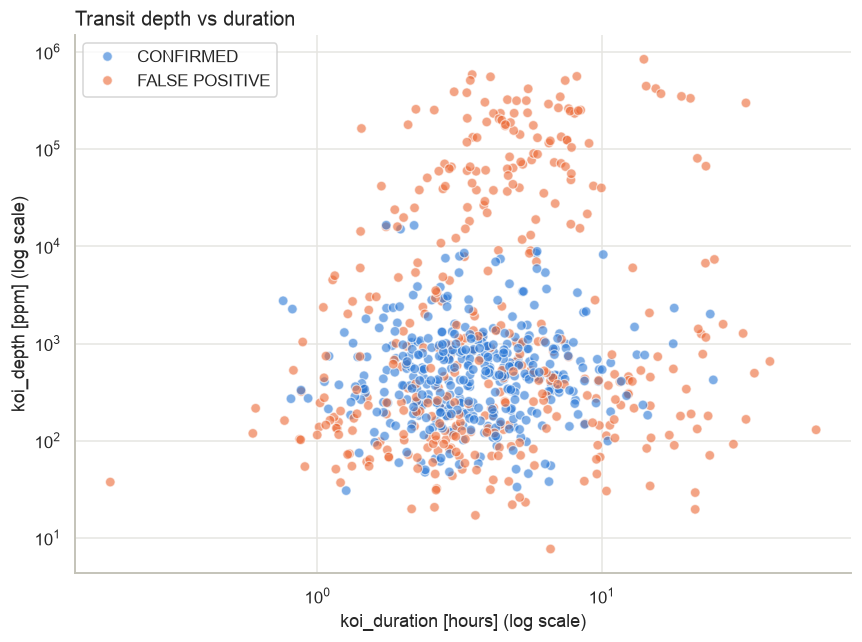

In [8]:
# Shuffle the signals so the dots are drawn in random order. Otherwise every orange
# dot would be drawn on top of every blue one and hide it where they overlap.
shuffled = df.sample(frac=1, random_state=42)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=shuffled, x="koi_duration", y="koi_depth",
    hue="koi_disposition", hue_order=CLASS_ORDER, palette=PALETTE,
    s=40, alpha=0.6, edgecolor="white", linewidth=0.8, ax=ax,
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Transit depth vs duration", loc="left", fontsize=13)
ax.set_xlabel("koi_duration [hours] (log scale)")
ax.set_ylabel("koi_depth [ppm] (log scale)")
ax.legend(title=None)
sns.despine(ax=ax)
fig.tight_layout()
path = RESULTS / "scatter_depth_vs_duration.png"
fig.savefig(path, dpi=150)
print("saved", path)
plt.show()

### What this chart shows

- Planets form one tight cloud in the middle.
- The top of the chart (very deep dips) is almost all orange: 115 false positives against 3 planets.
- But 127 false positives sit right inside the planet cloud.
- There's no slant: longer dips don't reliably come with deeper ones.

**In short:** two numbers together rule out the obvious false positives, but the hard ones look just like planets.

## Key takeaways

- **Depth is the best single clue.** Dips deeper than 2% are never planets.
- **Period and duration help only at the extremes.** Very short or very long periods, and very long dips, point to false positives.
- **Many false positives look exactly like planets in these numbers.** To catch them, the model needs the shape of the dip from the light curve.

## Saved charts

All charts are in `results/`: `hist_koi_period.png`, `hist_koi_depth.png`, `hist_koi_duration.png` and `scatter_depth_vs_duration.png`.